In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visuals
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("/content/ED_Waiting_Time_Data.csv")

### 1. Data Audit: ED

In [3]:
print(df)

     patient_id  visit_date day_of_week day_type         season arrival_time  \
0       PT00001  2025-01-25    Saturday  Weekend  Harmattan/Dry        12:46   
1       PT00002  2025-07-09   Wednesday  Weekday     Peak Rainy        22:21   
2       PT00003  2025-06-02      Monday  Weekday     Peak Rainy        12:40   
3       PT00004  2025-05-17    Saturday  Weekend    Early Rainy        08:34   
4       PT00005  2025-09-05      Friday  Weekday     Peak Rainy        17:17   
...         ...         ...         ...      ...            ...          ...   
5995    PT05996  2025-09-05      Friday  Weekday     Peak Rainy        09:05   
5996    PT05997  2025-03-01    Saturday  Weekend    Early Rainy        07:29   
5997    PT05998  2025-08-06   Wednesday  Weekday     Peak Rainy        10:40   
5998    PT05999  2025-07-13      Sunday  Weekend     Peak Rainy        11:44   
5999    PT06000  2025-07-07      Monday  Weekday     Peak Rainy        11:17   

      arrival_hour            departmen

In [4]:
df.head() ### shows the first 5 rows, like opening a spreadsheet and looking at the top.
          ##Purpose: confirm the file loaded properly and see what each column contains.

,patient_id,visit_date,day_of_week,day_type,season,arrival_time,arrival_hour,department,triage_priority,chief_complaint,age,gender,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
0,PT00001,2025-01-25,Saturday,Weekend,Harmattan/Dry,12:46,12,Maternity,4,Sprain,9,Male,9,6,4.3,9.1,46.8,12.9,73.1
1,PT00002,2025-07-09,Wednesday,Weekday,Peak Rainy,22:21,22,Maternity,4,Back pain,43,Male,8,3,4.4,9.8,33.1,9.1,56.4
2,PT00003,2025-06-02,Monday,Weekday,Peak Rainy,12:40,12,Maternity,4,Minor laceration,17,Male,12,3,6.1,8.9,25.6,11.2,51.8
3,PT00004,2025-05-17,Saturday,Weekend,Early Rainy,08:34,8,Emergency,4,Back pain,6,Male,10,4,7.7,7.4,47.2,17.0,79.3
4,PT00005,2025-09-05,Friday,Weekday,Peak Rainy,17:17,17,Outpatient - General,4,UTI symptoms,23,Female,11,2,7.0,6.6,56.4,18.0,88.0


In [5]:
df.tail() ### shows the last 5 rows.
           ### Purpose: check that the end of the file looks the same as the start, with no junk or cut-off rows.

,patient_id,visit_date,day_of_week,day_type,season,arrival_time,arrival_hour,department,triage_priority,chief_complaint,age,gender,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
5995,PT05996,2025-09-05,Friday,Weekday,Peak Rainy,09:05,9,Pediatrics,4,Back pain,25,Male,11,6,4.5,10.3,49.6,10.5,74.9
5996,PT05997,2025-03-01,Saturday,Weekend,Early Rainy,07:29,7,Outpatient - General,4,Back pain,52,Male,3,6,7.8,14.7,84.4,5.8,112.7
5997,PT05998,2025-08-06,Wednesday,Weekday,Peak Rainy,10:40,10,Emergency,4,UTI symptoms,24,Female,11,9,6.1,11.5,60.4,13.4,91.4
5998,PT05999,2025-07-13,Sunday,Weekend,Peak Rainy,11:44,11,Surgery Referral,2,Severe bleeding,19,Male,7,2,3.4,10.0,2.1,20.8,36.4
5999,PT06000,2025-07-07,Monday,Weekday,Peak Rainy,11:17,11,Maternity,4,Minor laceration,95,Male,12,3,5.3,7.5,27.5,16.5,56.7


In [6]:
print("the shape of the dataset is:", df.shape) ### returns two numbers: rows, then columns.
                                               ### Purpose: record the starting size, so any later row removal is traceable.

the shape of the dataset is: (6000, 19)


In [7]:
df.sample(10)

,patient_id,visit_date,day_of_week,day_type,season,arrival_time,arrival_hour,department,triage_priority,chief_complaint,age,gender,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
772,PT00773,2025-07-02,Wednesday,Weekday,Peak Rainy,08:05,8,Outpatient - General,4,Back pain,28,Female,12,7,8.3,11.2,70.8,15.6,105.9
3041,PT03042,2025-06-09,Monday,Weekday,Peak Rainy,05:41,5,Maternity,3,Asthma exacerbation,21,Female,8,1,5.2,9.9,31.3,22.1,68.5
334,PT00335,2025-03-07,Friday,Weekday,Early Rainy,11:50,11,Emergency,4,Back pain,27,Female,11,4,3.3,8.2,39.5,18.5,69.5
2854,PT02855,2025-03-01,Saturday,Weekend,Early Rainy,21:45,21,Pediatrics,2,Stroke symptoms,30,Female,5,6,7.3,7.3,15.2,19.5,49.3
1677,PT01678,2025-01-23,Thursday,Weekday,Harmattan/Dry,16:00,16,Outpatient - General,3,Moderate fracture,27,Male,11,6,4.6,8.6,25.9,14.6,53.7
4268,PT04269,2025-01-08,Wednesday,Weekday,Harmattan/Dry,00:09,0,Maternity,5,Prescription refill,44,Male,9,1,4.2,4.8,51.2,6.5,66.7
5855,PT05856,2025-04-27,Sunday,Weekend,Early Rainy,18:01,18,Outpatient - General,4,Sprain,7,Male,10,13,4.7,9.7,73.8,20.4,108.6
3505,PT03506,2025-03-24,Monday,Weekday,Early Rainy,11:21,11,Outpatient - General,4,Sprain,29,Male,13,6,8.3,11.8,44.5,19.7,84.3
308,PT00309,2025-05-07,Wednesday,Weekday,Early Rainy,04:02,4,Outpatient - General,3,High fever,24,Female,5,0,7.0,11.9,56.3,20.9,96.0
3574,PT03575,2025-05-10,Saturday,Weekend,Early Rainy,07:59,7,Maternity,3,Persistent vomiting,29,Female,8,4,5.8,10.9,45.5,17.5,79.8


In [8]:
print("column")
print(df.columns)

column
Index(['patient_id', 'visit_date', 'day_of_week', 'day_type', 'season',
       'arrival_time', 'arrival_hour', 'department', 'triage_priority',
       'chief_complaint', 'age', 'gender', 'staff_on_duty',
       'patients_in_queue_at_arrival', 'registration_time_minutes',
       'triage_time_minutes', 'wait_time_to_provider_minutes',
       'consultation_duration_minutes', 'total_visit_duration_minutes'],
      dtype='object')


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   patient_id                     6000 non-null   object 
 1   visit_date                     6000 non-null   object 
 2   day_of_week                    6000 non-null   object 
 3   day_type                       6000 non-null   object 
 4   season                         6000 non-null   object 
 5   arrival_time                   6000 non-null   object 
 6   arrival_hour                   6000 non-null   int64  
 7   department                     6000 non-null   object 
 8   triage_priority                6000 non-null   int64  
 9   chief_complaint                5880 non-null   object 
 10  age                            6000 non-null   int64  
 11  gender                         6000 non-null   object 
 12  staff_on_duty                  6000 non-null   i

In [10]:
df.describe()

,arrival_hour,triage_priority,age,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
count,6000.00000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,13.43700,3.486000,33.718500,10.165333,5.270167,5.986750,8.065117,42.044583,14.867183,70.964050
std,5.16383,0.979607,21.963591,2.357242,3.155604,1.993609,2.931422,23.039124,5.903230,23.036002
min,0.00000,1.000000,0.000000,3.000000,0.000000,1.000000,2.000000,0.000000,5.000000,15.100000
25%,9.00000,3.000000,17.000000,9.000000,3.000000,4.600000,6.000000,25.700000,10.500000,54.600000
50%,13.00000,4.000000,29.000000,11.000000,5.000000,6.000000,8.100000,42.600000,14.700000,71.150000
75%,18.00000,4.000000,46.000000,12.000000,7.000000,7.300000,10.100000,58.900000,18.900000,87.200000
max,23.00000,5.000000,95.000000,16.000000,20.000000,12.700000,19.000000,115.500000,40.000000,145.200000


In [11]:
df.isnull().sum()

,0
patient_id,0
visit_date,0
day_of_week,0
day_type,0
season,0
arrival_time,0
arrival_hour,0
department,0
triage_priority,0
chief_complaint,120


In [12]:
df.duplicated().sum() ## checking for duplicate rows

np.int64(0)

In [13]:
# Is the same patient listed more than once?
df["patient_id"].duplicated().sum()

np.int64(0)

In [14]:
# How many waits are exactly zero?
(df["wait_time_to_provider_minutes"] == 0).sum()

np.int64(314)

In [15]:
# Check the category labels in each text column
for col in ["department", "gender", "season", "day_type", "day_of_week"]:
    print(df[col].value_counts())
    print()

department
Emergency               2087
Outpatient - General    1818
Pediatrics               871
Surgery Referral         629
Maternity                595
Name: count, dtype: int64

gender
Male      3002
Female    2998
Name: count, dtype: int64

season
Peak Rainy       2581
Early Rainy      2087
Harmattan/Dry    1332
Name: count, dtype: int64

day_type
Weekday    4351
Weekend    1649
Name: count, dtype: int64

day_of_week
Monday       920
Friday       893
Thursday     853
Tuesday      850
Wednesday    835
Saturday     827
Sunday       822
Name: count, dtype: int64



In [16]:
# Do departments and gender look sensible together?
pd.crosstab(df["department"], df["gender"])

gender,Female,Male
department,,
Emergency,1052,1035
Maternity,284,311
Outpatient - General,902,916
Pediatrics,441,430
Surgery Referral,319,310


In [17]:
# Who are the zero-wait patients, by triage priority?
zero_wait = df[df["wait_time_to_provider_minutes"] == 0]
print(zero_wait["triage_priority"].value_counts().sort_index())

triage_priority
1     98
2    200
3     16
Name: count, dtype: int64


In [18]:
# What date range does the data cover?
print(df["visit_date"].min(), "to", df["visit_date"].max())

2025-01-01 to 2025-09-27


In [19]:
# Check the category labels in each text column
for col in ["department", "gender", "season", "day_type", "day_of_week"]:
    print(df[col].value_counts())
    print()

department
Emergency               2087
Outpatient - General    1818
Pediatrics               871
Surgery Referral         629
Maternity                595
Name: count, dtype: int64

gender
Male      3002
Female    2998
Name: count, dtype: int64

season
Peak Rainy       2581
Early Rainy      2087
Harmattan/Dry    1332
Name: count, dtype: int64

day_type
Weekday    4351
Weekend    1649
Name: count, dtype: int64

day_of_week
Monday       920
Friday       893
Thursday     853
Tuesday      850
Wednesday    835
Saturday     827
Sunday       822
Name: count, dtype: int64



In [20]:
#  Does arrival_hour match the hour inside arrival_time?
hour_from_time = df["arrival_time"].str[:2].astype(int)
print("Hour mismatches:", (hour_from_time != df["arrival_hour"]).sum())




Hour mismatches: 0


In [21]:
#  Does day_of_week match the visit date?
dates = pd.to_datetime(df["visit_date"])
print("Day-of-week mismatches:", (dates.dt.day_name() != df["day_of_week"]).sum())


Day-of-week mismatches: 0


In [22]:
#  Do the four stages add up to total visit time?
stage_sum = (df["registration_time_minutes"] + df["triage_time_minutes"]
             + df["wait_time_to_provider_minutes"] + df["consultation_duration_minutes"])
print("Total-time mismatches:", ((stage_sum - df["total_visit_duration_minutes"]).abs() > 0.5).sum())

Total-time mismatches: 0


## 2. Data Cleaning
The raw data (`df`) stays unchanged. All changes are made on a working copy (`e_d`) and recorded in the decision log. No rows are deleted.

In [23]:
e_d = df.copy()  # creating a copy from the original dataset # working copy; df stays untouched

In [24]:
#fill the missing complaints
e_d["chief_complaint"] = e_d["chief_complaint"].fillna("Unknown")
print("Missing chief_complaint now:", e_d["chief_complaint"].isnull().sum())

Missing chief_complaint now: 0


In [25]:
#convert the date

e_d["visit_date"] = pd.to_datetime(e_d["visit_date"])
print(e_d["visit_date"].dtype)

datetime64[ns]


In [26]:
#prove that nothing was lost
print("Rows in raw data (df):", len(df))
print("Rows in cleaned data (e_d):", len(e_d))
print("Raw data still has", df["chief_complaint"].isnull().sum(), "missing complaints")

Rows in raw data (df): 6000
Rows in cleaned data (e_d): 6000
Raw data still has 120 missing complaints


In [27]:
#save the cleaned file
e_d.to_csv("ED_Waiting_Time_Cleaned.csv", index=False)

### Cleaning summary
- 120 missing chief_complaint values labelled "Unknown" (no rows removed).
- visit_date converted to datetime.
- Rows: 6,000 before and after. Raw data unchanged.
- Zero waits (314) retained and not imputed, as wait time is the target variable.
- Cleaned data saved separately as ED_Waiting_Time_Cleaned.csv.

## 3. EDA: Understanding the Target Variable
Target: wait_time_to_provider_minutes, the time from the end of triage until a provider sees the patient.

In [28]:
#summary of the target
e_d["wait_time_to_provider_minutes"].describe()

,wait_time_to_provider_minutes
count,6000.000000
mean,42.044583
std,23.039124
min,0.000000
25%,25.700000
50%,42.600000
75%,58.900000
max,115.500000


In [29]:
# The wait that 10%, 50%, 90% and 95% of patients are below
e_d["wait_time_to_provider_minutes"].quantile([0.10, 0.50, 0.90, 0.95])

,wait_time_to_provider_minutes
0.10,9.0
0.50,42.6
0.90,71.7
0.95,79.4


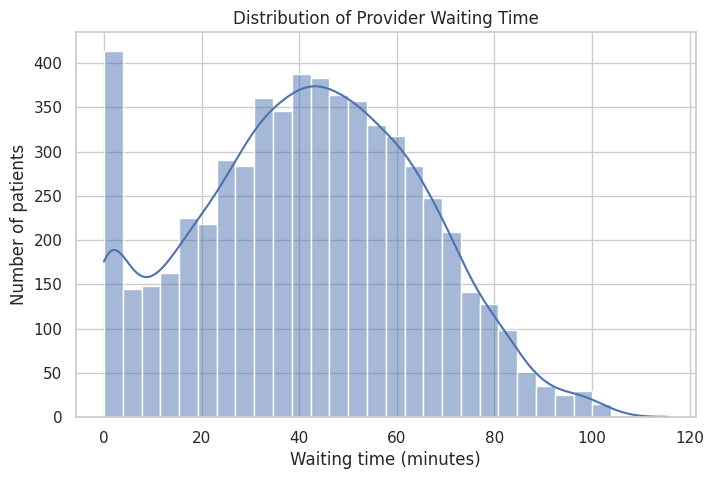

In [30]:
#distribution chart
plt.figure(figsize=(8, 5))
sns.histplot(e_d["wait_time_to_provider_minutes"], bins=30, kde=True)
plt.title("Distribution of Provider Waiting Time")
plt.xlabel("Waiting time (minutes)")
plt.ylabel("Number of patients")
plt.show()

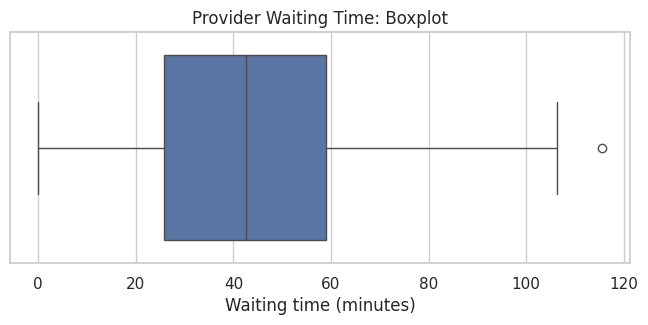

In [31]:
#boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(x=e_d["wait_time_to_provider_minutes"])
plt.title("Provider Waiting Time: Boxplot")
plt.xlabel("Waiting time (minutes)")
plt.show()

In [32]:
#skewness and long waits
print("Skewness:", round(e_d["wait_time_to_provider_minutes"].skew(), 2))
print("Share of waits over 60 minutes:",
      round((e_d["wait_time_to_provider_minutes"] > 60).mean() * 100, 1), "%")

Skewness: 0.02
Share of waits over 60 minutes: 23.3 %


### Target variable findings
- Average provider wait is about 42 minutes (median 42.6); the distribution is symmetrical (skewness 0.02).
- 23.3% of patients wait more than 60 minutes; the slowest 10% wait over 72 minutes.
- A distinct spike at 0–3 minutes reflects the 314 zero-wait patients, concentrated in triage priority 1–2.
- Maximum wait is 115.5 minutes; no extreme outliers.
- Note for modelling: the spike at zero may affect linear models.

## 4. EDA: Waiting Time by Triage Priority and Department

In [33]:
# waiting time by department and triage priority
#summary by triage priority

by_triage = e_d.groupby("triage_priority")["wait_time_to_provider_minutes"].agg(["count", "mean", "median"])
by_triage["p90"] = e_d.groupby("triage_priority")["wait_time_to_provider_minutes"].quantile(0.90)
by_triage.round(1)

,count,mean,median,p90
triage_priority,,,,
1,179,5.2,0.0,16.8
2,681,11.1,7.2,29.9
3,2096,33.2,32.6,53.3
4,2133,53.0,52.5,73.2
5,911,67.1,67.0,87.3


In [34]:
#summary by department

by_dept = e_d.groupby("department")["wait_time_to_provider_minutes"].agg(["count", "mean", "median"])
by_dept["p90"] = e_d.groupby("department")["wait_time_to_provider_minutes"].quantile(0.90)
by_dept.round(1)

,count,mean,median,p90
department,,,,
Emergency,2087,36.1,36.4,65.3
Maternity,595,31.2,31.3,59.4
Outpatient - General,1818,51.7,53.0,79.8
Pediatrics,871,40.3,40.9,69.2
Surgery Referral,629,46.6,47.6,73.0


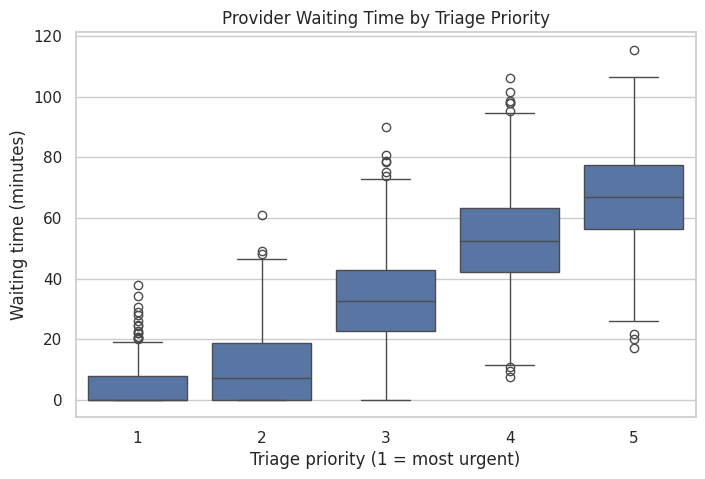

In [35]:
#chart by triage priority

plt.figure(figsize=(8, 5))
sns.boxplot(data=e_d, x="triage_priority", y="wait_time_to_provider_minutes")
plt.title("Provider Waiting Time by Triage Priority")
plt.xlabel("Triage priority (1 = most urgent)")
plt.ylabel("Waiting time (minutes)")
plt.show()

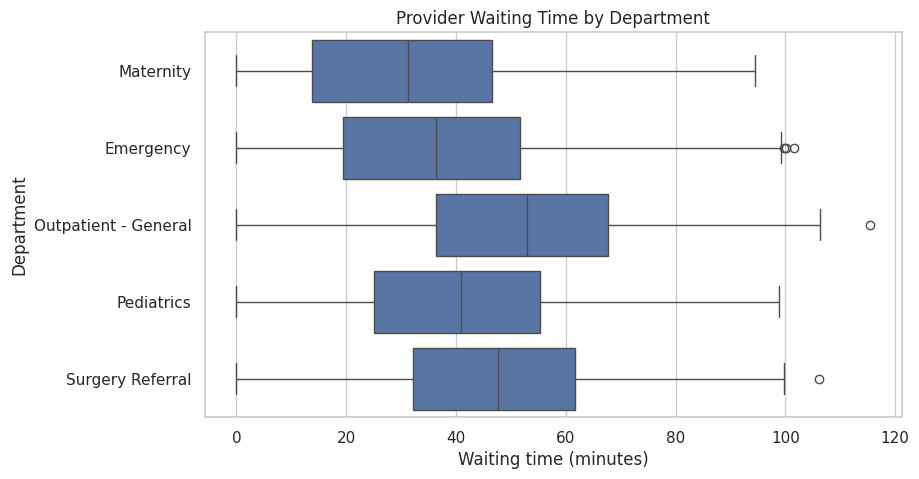

In [36]:
# chart by department

plt.figure(figsize=(9, 5))
sns.boxplot(data=e_d, x="wait_time_to_provider_minutes", y="department")
plt.title("Provider Waiting Time by Department")
plt.xlabel("Waiting time (minutes)")
plt.ylabel("Department")
plt.show()

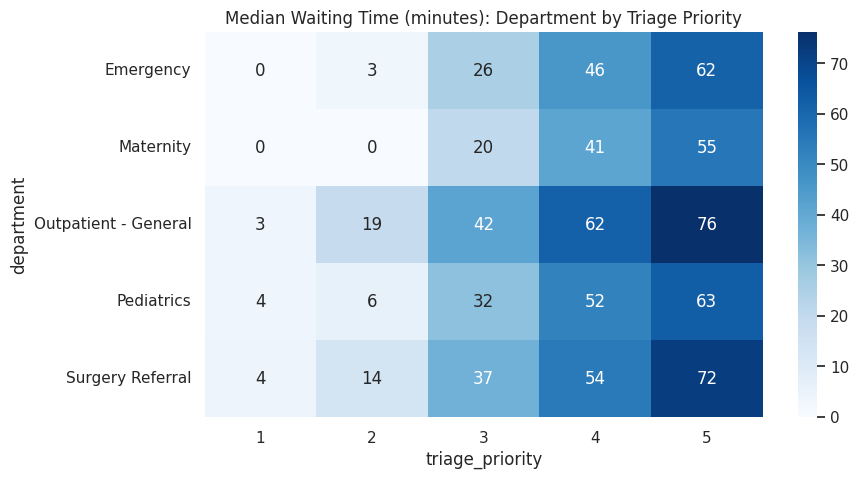

In [37]:
# department and triage together

pivot = e_d.pivot_table(values="wait_time_to_provider_minutes",
                        index="department", columns="triage_priority", aggfunc="median")
plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues")
plt.title("Median Waiting Time (minutes): Department by Triage Priority")
plt.show()

### Findings: waiting time by triage priority and department
- Waiting time rises steadily as urgency falls: mean wait is 5 minutes for priority 1 and 67 minutes for priority 5.
- Outpatient - General has the longest waits (mean 52 min, 90th percentile 80 min); Maternity the shortest (mean 31 min).
- The department ranking holds within each triage level, so it is not only explained by patient mix.
- Priority 2 patients wait considerably longer in Outpatient - General (median 19 min) and Surgery Referral (14 min) than in Emergency (3 min).
- These are associations; the data does not show why departments differ.

## 5. EDA: When Pressure Builds (Arrival Hour, Day Type, Season)

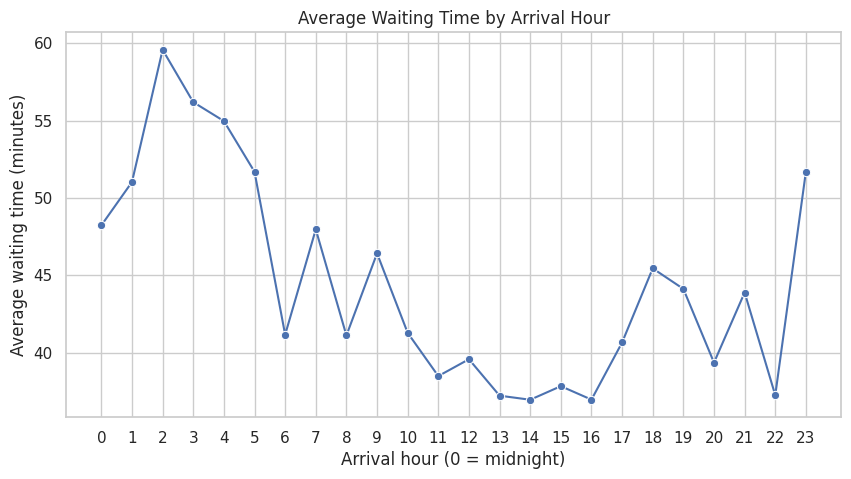

In [38]:
#waiting time by arrival hour

by_hour = e_d.groupby("arrival_hour")["wait_time_to_provider_minutes"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=by_hour, x="arrival_hour", y="wait_time_to_provider_minutes", marker="o")
plt.xticks(range(0, 24))
plt.title("Average Waiting Time by Arrival Hour")
plt.xlabel("Arrival hour (0 = midnight)")
plt.ylabel("Average waiting time (minutes)")
plt.show()

In [39]:
#tables by day type, season and weekday

for col in ["day_type", "season", "day_of_week"]:
    print(e_d.groupby(col)["wait_time_to_provider_minutes"].agg(["count", "mean", "median"]).round(1))
    print()

          count  mean  median
day_type                     
Weekday    4351  37.9    39.0
Weekend    1649  53.0    54.8

               count  mean  median
season                            
Early Rainy     2087  42.3    42.7
Harmattan/Dry   1332  41.1    41.7
Peak Rainy      2581  42.3    42.7

             count  mean  median
day_of_week                     
Friday         893  38.2    38.9
Monday         920  38.4    39.6
Saturday       827  53.5    55.9
Sunday         822  52.5    53.8
Thursday       853  37.5    39.1
Tuesday        850  36.8    37.6
Wednesday      835  38.5    39.3



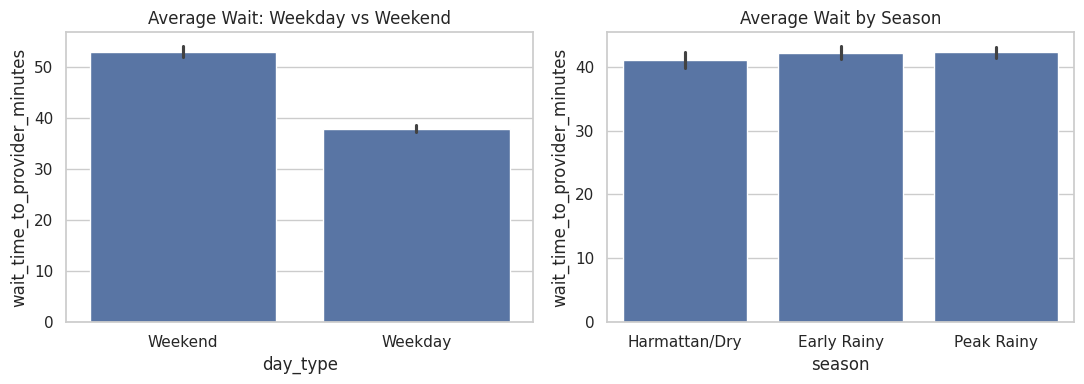

In [40]:
#charts for day type and season

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=e_d, x="day_type", y="wait_time_to_provider_minutes", ax=axes[0])
axes[0].set_title("Average Wait: Weekday vs Weekend")
sns.barplot(data=e_d, x="season", y="wait_time_to_provider_minutes",
            order=["Harmattan/Dry", "Early Rainy", "Peak Rainy"], ax=axes[1])
axes[1].set_title("Average Wait by Season")
plt.tight_layout()
plt.show()

### Findings: when pressure builds
- Weekend visits wait about 15 minutes longer on average than weekday visits (53.0 vs 37.9); the gap holds within every triage priority.
- Waits are longest for overnight arrivals (11 pm to 5 am), peaking around 2 am at roughly 60 minutes, and shortest in the early afternoon (about 37 minutes).
- Overnight and weekend periods also have fewer staff on duty, suggesting staffing levels as a factor to investigate; this is an association, not proof of cause.
- Overnight hours have few patients (under 90 per hour), so those averages are less stable.
- Season shows almost no difference in average waits (41 to 42 minutes). The data covers January to September 2025 only.

## 6. EDA: Queue Size, Staffing and Correlation

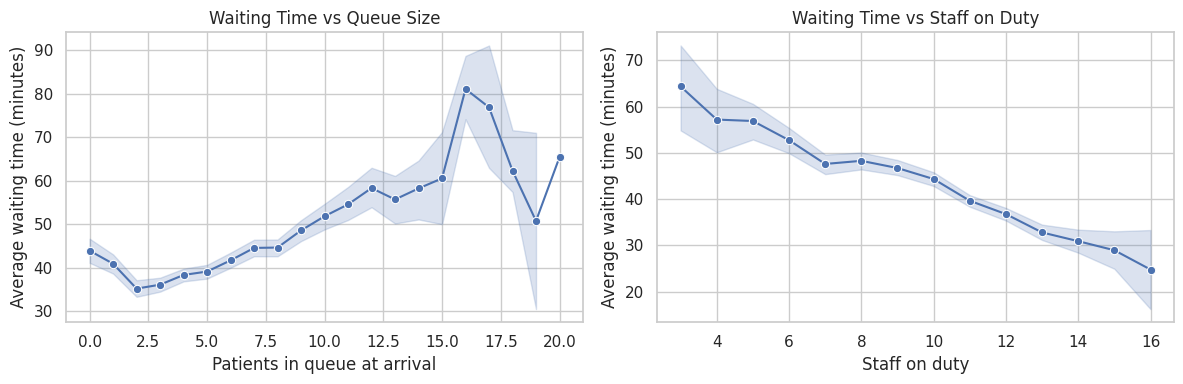

In [41]:
#queue and staffing against waiting time

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=e_d, x="patients_in_queue_at_arrival", y="wait_time_to_provider_minutes", marker="o", ax=axes[0])
axes[0].set_title("Waiting Time vs Queue Size")
axes[0].set_xlabel("Patients in queue at arrival")
axes[0].set_ylabel("Average waiting time (minutes)")
sns.lineplot(data=e_d, x="staff_on_duty", y="wait_time_to_provider_minutes", marker="o", ax=axes[1])
axes[1].set_title("Waiting Time vs Staff on Duty")
axes[1].set_xlabel("Staff on duty")
axes[1].set_ylabel("Average waiting time (minutes)")
plt.tight_layout()
plt.show()

In [42]:
#correlation with the target

numeric = e_d.select_dtypes(include="number")
numeric.corr()["wait_time_to_provider_minutes"].sort_values(ascending=False).round(2)

,wait_time_to_provider_minutes
wait_time_to_provider_minutes,1.00
total_visit_duration_minutes,0.96
triage_priority,0.76
patients_in_queue_at_arrival,0.20
triage_time_minutes,0.02
registration_time_minutes,-0.01
age,-0.02
arrival_hour,-0.06
consultation_duration_minutes,-0.18
staff_on_duty,-0.28


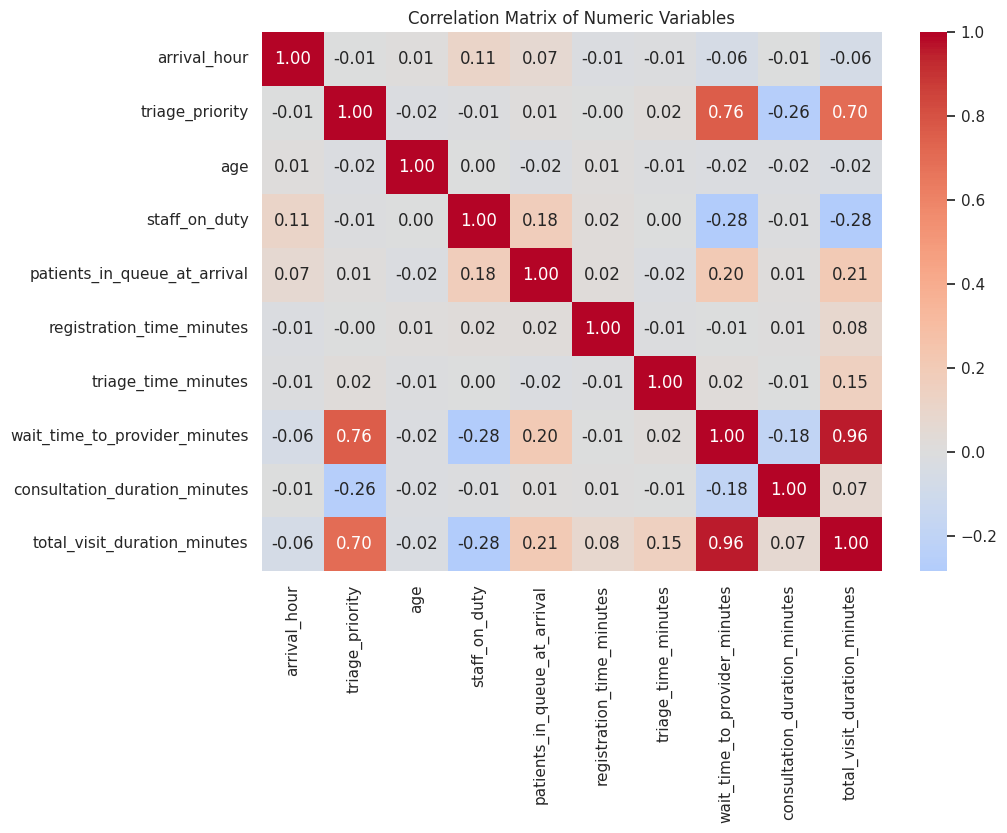

In [43]:
#correlation heatmap

plt.figure(figsize=(10, 7))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numeric Variables")
plt.show()